# Trabajo Final Integrador
## Detección de cáncer de mama con Machine Learning

**Universidad Provincial del Sudoeste (UPSO)**
**Materia:** Elementos de Aprendizaje de Máquina y Big Data
**Docentes:** Ing. Valentín Barco – Dr. Claudio A. Delrieux
**Carrera:** T.U. Tecnologías de Programación
**Grupo:** 42
**Integrante:** Leonardo Fiz
**Fecha:** 17/11/2026

## 1. Introducción

En este trabajo elegí un tema de salud: saber si un tumor de mama es benigno o maligno a partir de medidas que se toman de las células en un estudio (punción).

La idea es aplicar lo que vimos en la materia siguiendo el ciclo de vida del análisis de datos:

1. Evaluación del caso: qué problema quiero resolver.
2. Identificación y adquisición de datos: de dónde salen los datos.
3. Validación y limpieza: revisar que los datos estén bien.
4. Análisis y visualización: estadística descriptiva, gráficos y una prueba de hipótesis.
5. Modelos de Machine Learning: clasificación (KNN, Bayes, SVM y Árbol de Decisión), reducción de dimensionalidad (PCA) y clustering (K-medias).
6. Uso de los resultados: conclusiones.

Objetivo: armar un modelo que, con las medidas de las células, diga si el tumor es maligno o benigno, y comparar varios modelos para ver cuál anda mejor.

## 2. Librerías que uso

- pandas: para manejar los datos en un DataFrame.
- numpy: para cálculos.
- matplotlib: para los gráficos.
- scipy: para la prueba de hipótesis.
- scikit-learn: trae el dataset y los modelos de Machine Learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
SEMILLA = 42   # para que los resultados den siempre igual

## 3. Carga de datos

El dataset se llama Breast Cancer Wisconsin (Diagnostic). Son datos reales de 569 pacientes del hospital de la Universidad de Wisconsin (EE.UU.). Viene incluido en scikit-learn, así que no hace falta descargar nada.

Cada fila es un paciente y tiene **30 columnas con medidas** de los núcleos de las células (radio, textura, perímetro, área, suavidad, etc.) y una columna con el diagnóstico.

Son datos estructurados, porque están ordenados en filas y columnas, como una planilla.

In [2]:
datos = load_breast_cancer(as_frame=True)
df = datos.frame.copy()

# En el dataset original 0 = maligno y 1 = benigno.
# Lo doy vuelta para que 1 = maligno (que es lo que quiero detectar).
df['maligno'] = 1 - df['target']
df['diagnostico'] = df['maligno'].map({1: 'Maligno', 0: 'Benigno'})
df = df.drop(columns='target')

print('Filas y columnas:', df.shape)
df.head()

Filas y columnas: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,maligno,diagnostico
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1,Maligno
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1,Maligno
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1,Maligno
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1,Maligno
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1,Maligno


In [3]:
# Tipos de datos de cada columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

## 4. Validación y limpieza de datos

Antes de analizar reviso dos cosas: si hay datos faltantes y si hay filas repetidas.

In [4]:
print('Datos faltantes en total:', df.isnull().sum().sum())
print('Filas duplicadas:', df.duplicated().sum())

Datos faltantes en total: 0
Filas duplicadas: 0


No hay datos faltantes ni filas repetidas, así que no hace falta borrar ni completar nada. Los datos están limpios.

## 5. Análisis descriptivo

### 5.1 ¿Cuántos casos hay de cada tipo?

             Cantidad  Porcentaje (%)
diagnostico                          
Benigno           357            62.7
Maligno           212            37.3


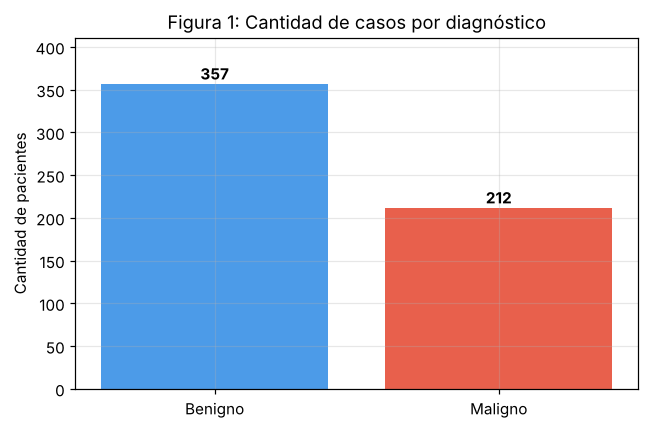

In [5]:
conteo = df['diagnostico'].value_counts()
porcentaje = (df['diagnostico'].value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({'Cantidad': conteo, 'Porcentaje (%)': porcentaje}))

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(conteo.index, conteo.values, color=['#4C9BE8', '#E8604C'])
for b in barras:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 5, int(b.get_height()), ha='center', fontweight='bold')
ax.set_ylim(0, conteo.max() * 1.15)
ax.set_title('Figura 1: Cantidad de casos por diagnóstico')
ax.set_ylabel('Cantidad de pacientes')
plt.tight_layout()
plt.show()

Hay más casos benignos que malignos, pero la diferencia no es tan grande. Por eso, cuando separe los datos para entrenar, voy a mantener la misma proporción en las dos partes.

### 5.2 Estadística descriptiva

Calculo la media, la varianza y el desvío estándar de 4 medidas importantes, separando benignos y malignos.

In [6]:
medidas = ['mean radius', 'mean texture', 'mean perimeter', 'mean area']
tabla = df.groupby('diagnostico')[medidas].agg(['mean', 'var', 'std']).round(2).T
tabla.columns.name = None
tabla

Benigno    Maligno
mean radius    mean     12.15      17.46
               var       3.17      10.27
               std       1.78       3.20
mean texture   mean     17.91      21.60
               var      15.96      14.28
               std       4.00       3.78
mean perimeter mean     78.08     115.37
               var     139.42     477.63
               std      11.81      21.85
mean area      mean    462.79     978.38
               var   18033.03  135378.36
               std     134.29     367.94

Se ve una diferencia clara: los tumores malignos tienen células más grandes (más radio, perímetro y área). También el desvío es más grande en los malignos, o sea que sus valores varían más.

### 5.3 Distribución del radio

Comparo cómo se distribuye el radio medio en cada grupo.

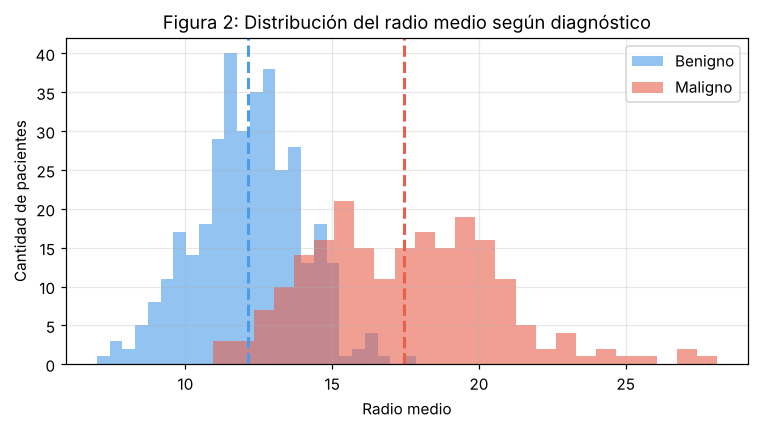

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for diag, color in [('Benigno', '#4C9BE8'), ('Maligno', '#E8604C')]:
    valores = df.loc[df['diagnostico'] == diag, 'mean radius']
    ax.hist(valores, bins=25, alpha=0.6, color=color, label=diag)
    ax.axvline(valores.mean(), color=color, linestyle='--', linewidth=2)
ax.set_title('Figura 2: Distribución del radio medio según diagnóstico')
ax.set_xlabel('Radio medio')
ax.set_ylabel('Cantidad de pacientes')
ax.legend()
plt.tight_layout()
plt.show()

Las dos campanas están corridas: los benignos se juntan en radios chicos y los malignos en radios más grandes. Las líneas punteadas marcan el promedio de cada grupo. Hay una zona donde se mezclan, y ahí es donde un modelo puede equivocarse.

### 5.4 Comparación con diagramas de caja

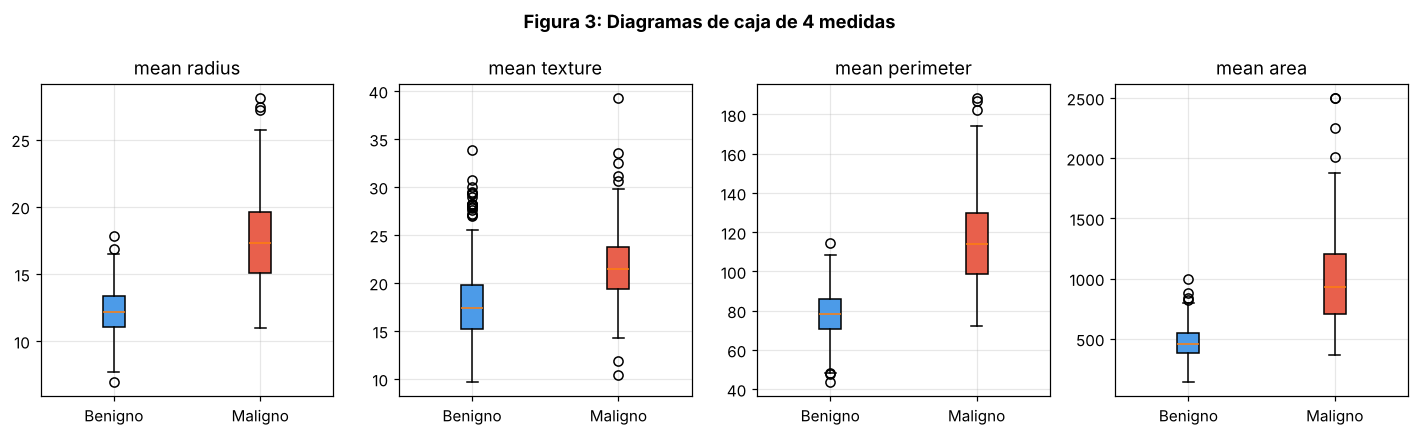

In [8]:
fig, ejes = plt.subplots(1, 4, figsize=(13, 4))
for ax, medida in zip(ejes, medidas):
    grupos = [df.loc[df['diagnostico'] == d, medida] for d in ['Benigno', 'Maligno']]
    caja = ax.boxplot(grupos, patch_artist=True)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Benigno', 'Maligno'])
    for parte, color in zip(caja['boxes'], ['#4C9BE8', '#E8604C']):
        parte.set_facecolor(color)
    ax.set_title(medida)
fig.suptitle('Figura 3: Diagramas de caja de 4 medidas', fontweight='bold')
plt.tight_layout()
plt.show()

En las 4 medidas la caja de los malignos está más arriba. La textura es la que menos separa a los dos grupos.

### 5.5 Correlación entre medidas (mapa de calor)

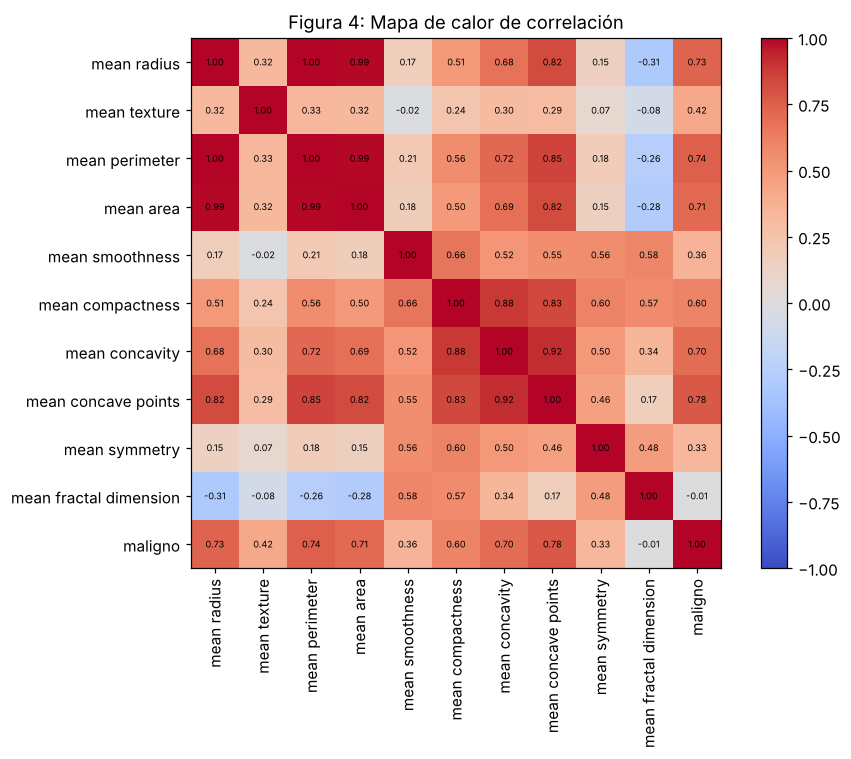

Correlación de cada medida con "maligno" (de mayor a menor):
mean concave points       0.78
mean perimeter            0.74
mean radius               0.73
mean area                 0.71
mean concavity            0.70
mean compactness          0.60
mean texture              0.42
mean smoothness           0.36
mean symmetry             0.33
mean fractal dimension   -0.01
Name: maligno, dtype: float64


In [9]:
cols_media = [c for c in df.columns if c.startswith('mean')]
corr = df[cols_media + ['maligno']].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=6)
fig.colorbar(im)
ax.set_title('Figura 4: Mapa de calor de correlación')
ax.grid(False)
plt.tight_layout()
plt.show()

print('Correlación de cada medida con "maligno" (de mayor a menor):')
print(corr['maligno'].drop('maligno').sort_values(ascending=False).round(2))

- El radio, el perímetro y el área están casi 100% correlacionados entre sí. Tiene lógica: si el radio es más grande, el perímetro y el área también.
- Las medidas que más se relacionan con que el tumor sea maligno son los puntos cóncavos (concave points), el perímetro, el radio y el área.
- La dimensión fractal casi no tiene relación con el diagnóstico.

### 5.6 Prueba de hipótesis

Quiero comprobar con un test estadístico que el radio de los malignos es distinto al de los benignos, y que no es casualidad.

- **Hipótesis nula (H0):** el radio medio es igual en los dos grupos.
- **Hipótesis alternativa (H1):** el radio medio es distinto.

Uso la prueba t de Student (versión de Welch, que no supone que los dos grupos tengan la misma varianza), con un nivel de significancia de 0,05.

In [10]:
radio_ben = df.loc[df['diagnostico'] == 'Benigno', 'mean radius']
radio_mal = df.loc[df['diagnostico'] == 'Maligno', 'mean radius']
t, p = stats.ttest_ind(radio_mal, radio_ben, equal_var=False)
print(f'Media benignos: {radio_ben.mean():.2f}   Media malignos: {radio_mal.mean():.2f}')
print(f'Estadístico t = {t:.2f}')
print(f'Valor p = {p:.2e}')
print('Se rechaza H0' if p < 0.05 else 'No se rechaza H0')

Media benignos: 12.15   Media malignos: 17.46
Estadístico t = 22.21
Valor p = 1.68e-64
Se rechaza H0


El valor p es muchísimo más chico que 0,05, así que rechazo la hipótesis nula: la diferencia en el radio entre benignos y malignos es real y no es casualidad.

## 6. Preparación de los datos para los modelos

1. X son las 30 medidas (atributos) e y es el diagnóstico (1 = maligno, 0 = benigno).
2. Separo los datos: **80% para entrenar** y **20% para testear**. El modelo aprende con el 80% y después lo pruebo con el 20% que nunca vio. Uso `stratify` para que las dos partes tengan la misma proporción de malignos.
3. Escalado: las medidas tienen escalas muy distintas (el área llega a más de 2000 y la suavidad está cerca de 0,1). Modelos como KNN y SVM trabajan con distancias, así que escalo todo con `StandardScaler` para que cada medida quede con media 0 y desvío 1. Lo pongo dentro de un *pipeline* para que el escalado aprenda solo de los datos de entrenamiento.

In [11]:
X = df[datos.feature_names]
y = df['maligno']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

print('Entrenamiento:', X_train.shape[0], 'pacientes')
print('Testeo:', X_test.shape[0], 'pacientes')
print('Proporción de malignos en entrenamiento:', round(y_train.mean(), 3))
print('Proporción de malignos en testeo:', round(y_test.mean(), 3))

Entrenamiento: 455 pacientes
Testeo: 114 pacientes
Proporción de malignos en entrenamiento: 0.374
Proporción de malignos en testeo: 0.368


## 7. Modelos de clasificación

Pruebo 4 modelos que vimos en la materia:

| Modelo | Idea simple |
|---|---|
| KNN (K vecinos más cercanos) | Mira los K pacientes más parecidos y elige el diagnóstico que más se repite. |
| Bayes (Naive Bayes Gaussiano) | Calcula la probabilidad de cada diagnóstico usando el teorema de Bayes. |
| SVM (Máquina de Vectores de Soporte) | Busca la "frontera" que mejor separa a los dos grupos. |
| Árbol de Decisión | Hace preguntas del tipo "¿el radio es mayor a X?" hasta llegar a una respuesta. |

### 7.1 Elegir el mejor K para KNN

Antes de usar KNN tengo que elegir cuántos vecinos mirar. Pruebo K de 1 a 25 con **validación cruzada de 5 partes** sobre los datos de entrenamiento.

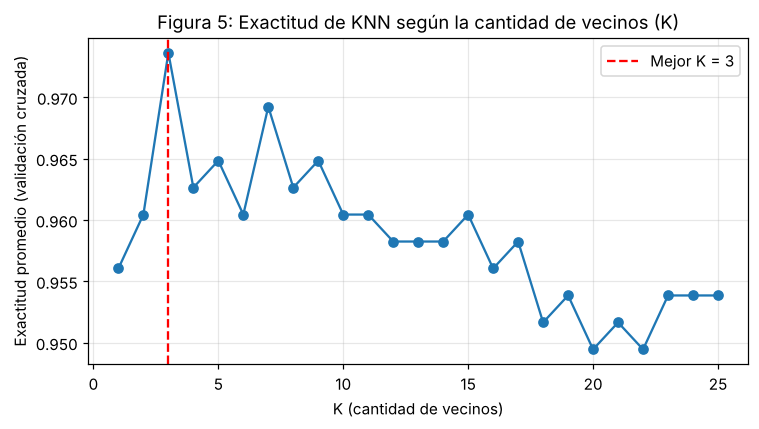

Mejor K: 3 - exactitud: 0.974


In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
valores_k = range(1, 26)
exactitud_k = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                               X_train, y_train, cv=cv).mean() for k in valores_k]
mejor_k = valores_k[int(np.argmax(exactitud_k))]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(valores_k, exactitud_k, marker='o')
ax.axvline(mejor_k, color='red', linestyle='--', label=f'Mejor K = {mejor_k}')
ax.set_title('Figura 5: Exactitud de KNN según la cantidad de vecinos (K)')
ax.set_xlabel('K (cantidad de vecinos)')
ax.set_ylabel('Exactitud promedio (validación cruzada)')
ax.legend()
plt.tight_layout()
plt.show()
print('Mejor K:', mejor_k, '- exactitud:', round(max(exactitud_k), 3))

### 7.2 Entrenamiento y testeo de los 4 modelos

Para cada modelo calculo:
- Exactitud (accuracy): de todos los pacientes, cuántos acertó.
- Precisión: de los que dijo "maligno", cuántos eran malignos de verdad.
- Sensibilidad (recall): de los malignos reales, cuántos detectó. Es la más importante en este caso, porque no detectar un cáncer es el peor error.
- **F1:** un promedio entre precisión y sensibilidad.
- AUC: el área bajo la curva ROC (1 es perfecto y 0,5 es como tirar una moneda).
- Validación cruzada: la exactitud promedio en 5 partes del entrenamiento, para ver si el resultado es estable.

In [13]:
modelos = {
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=mejor_k)),
    'Bayes': make_pipeline(StandardScaler(), GaussianNB()),
    'SVM': make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=SEMILLA)),
    'Árbol de Decisión': DecisionTreeClassifier(max_depth=4, random_state=SEMILLA),
}

resultados = []
probabilidades = {}
for nombre, modelo in modelos.items():
    cv_scores = cross_val_score(modelo, X_train, y_train, cv=cv)
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    # Puntaje de "qué tan maligno" para la curva ROC
    if hasattr(modelo, 'decision_function'):
        prob = modelo.decision_function(X_test)   # SVM da un puntaje en vez de probabilidad
    else:
        prob = modelo.predict_proba(X_test)[:, 1]
    probabilidades[nombre] = prob
    resultados.append({
        'Modelo': nombre,
        'Exactitud': accuracy_score(y_test, pred),
        'Precisión': precision_score(y_test, pred),
        'Sensibilidad': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'AUC': roc_auc_score(y_test, prob),
        'CV media': cv_scores.mean(),
        'CV desvío': cv_scores.std(),
    })

tabla_res = pd.DataFrame(resultados).set_index('Modelo').round(3)
tabla_res

,Exactitud,Precisión,Sensibilidad,F1,AUC,CV media,CV desvío
Modelo,,,,,,,
KNN,0.939,0.973,0.857,0.911,0.982,0.974,0.018
Bayes,0.921,0.923,0.857,0.889,0.989,0.938,0.026
SVM,0.974,1.000,0.929,0.963,0.995,0.971,0.005
Árbol de Decisión,0.912,0.944,0.810,0.872,0.877,0.921,0.038


### 7.3 Curva ROC

La curva ROC muestra qué tan bien separa cada modelo a malignos y benignos. Cuanto más pegada a la esquina de arriba a la izquierda, mejor.

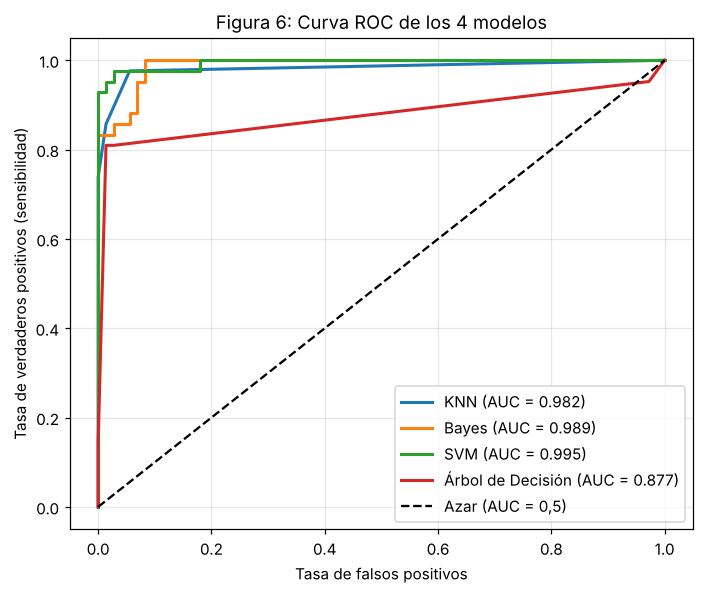

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nombre, prob in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, linewidth=2, label=f'{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})')
ax.plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0,5)')
ax.set_title('Figura 6: Curva ROC de los 4 modelos')
ax.set_xlabel('Tasa de falsos positivos')
ax.set_ylabel('Tasa de verdaderos positivos (sensibilidad)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 7.4 Comparación de los modelos

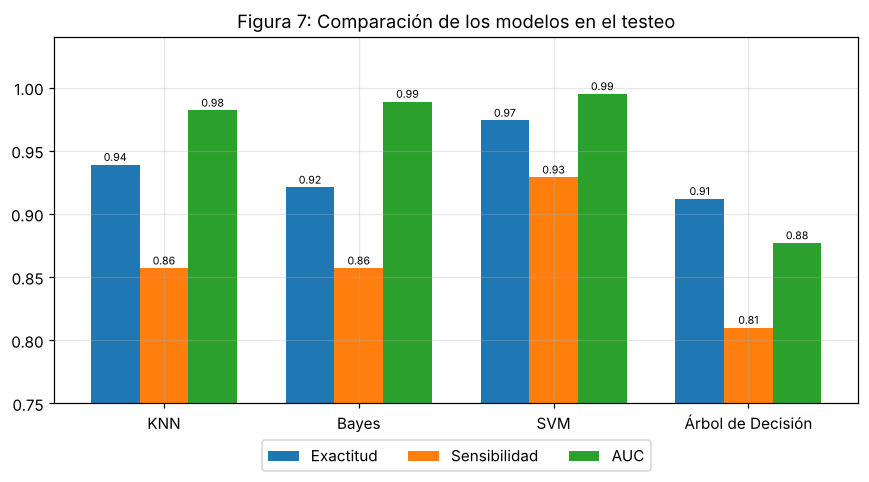

Mejor modelo: SVM


In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
metricas = ['Exactitud', 'Sensibilidad', 'AUC']
ancho = 0.25
x = np.arange(len(tabla_res))
for i, m in enumerate(metricas):
    barras = ax.bar(x + i*ancho, tabla_res[m], ancho, label=m)
    for b in barras:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.003, f'{b.get_height():.2f}',
                ha='center', fontsize=7)
ax.set_xticks(x + ancho)
ax.set_xticklabels(tabla_res.index)
ax.set_ylim(0.75, 1.04)
ax.set_title('Figura 7: Comparación de los modelos en el testeo')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3)
plt.tight_layout()
plt.show()

# El mejor: el de mayor exactitud; si empatan, el de mayor sensibilidad y después AUC
mejor = tabla_res.sort_values(['Exactitud', 'Sensibilidad', 'AUC'], ascending=False).index[0]
print('Mejor modelo:', mejor)

### 7.5 Matriz de confusión del mejor modelo

La matriz de confusión muestra en qué acertó y en qué se equivocó el modelo con los pacientes de testeo.

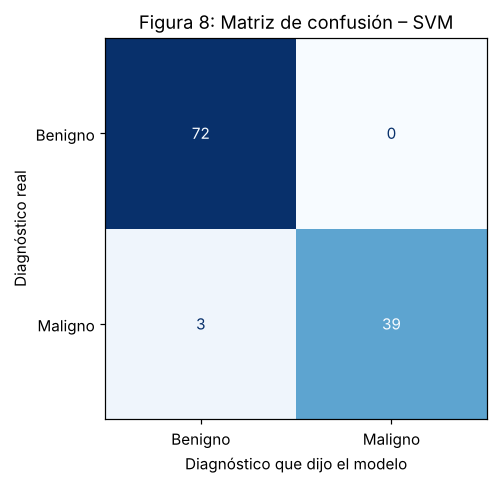

Benignos bien clasificados: 72
Malignos bien detectados: 39
Benignos que dijo maligno (falsa alarma): 0
Malignos que NO detectó: 3


In [16]:
pred_mejor = modelos[mejor].predict(X_test)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_mejor),
                       display_labels=['Benigno', 'Maligno']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Figura 8: Matriz de confusión – {mejor}')
ax.set_xlabel('Diagnóstico que dijo el modelo')
ax.set_ylabel('Diagnóstico real')
ax.grid(False)
plt.tight_layout()
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, pred_mejor).ravel()
print(f'Benignos bien clasificados: {vn}')
print(f'Malignos bien detectados: {vp}')
print(f'Benignos que dijo maligno (falsa alarma): {fp}')
print(f'Malignos que NO detectó: {fn}')

### 7.6 ¿Qué medidas usa más el Árbol de Decisión?

El árbol tiene la ventaja de que se puede ver qué medidas usa para decidir.

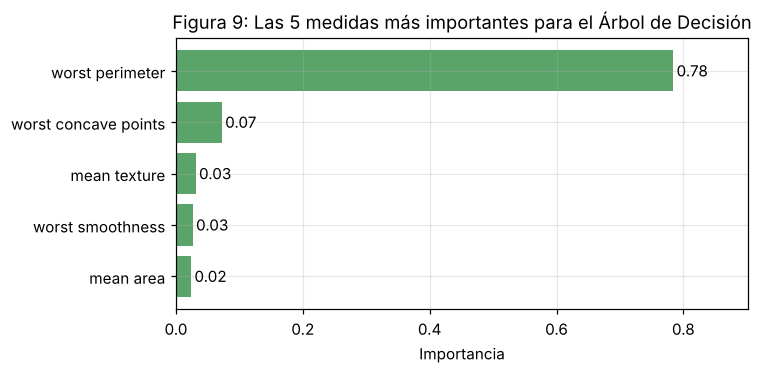

In [17]:
arbol = modelos['Árbol de Decisión']
importancia = pd.Series(arbol.feature_importances_, index=datos.feature_names).sort_values(ascending=False).head(5)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(importancia.index[::-1], importancia.values[::-1], color='#5AA469')
for i, v in enumerate(importancia.values[::-1]):
    ax.text(v + 0.005, i, f'{v:.2f}', va='center')
ax.set_title('Figura 9: Las 5 medidas más importantes para el Árbol de Decisión')
ax.set_xlabel('Importancia')
ax.set_xlim(0, importancia.max() * 1.15)
plt.tight_layout()
plt.show()

## 8. Reducción de dimensionalidad con PCA

Tengo 30 medidas, y es imposible dibujar 30 dimensiones. El PCA (Análisis de Componentes Principales) resume las 30 medidas en unas pocas "componentes" que juntan la mayor parte de la información. Uso 2 componentes para poder graficar a los pacientes en un plano.

Componente 1 explica el 44.3% de la información
Componente 2 explica el 19.0% de la información
Entre las dos: 63.2%


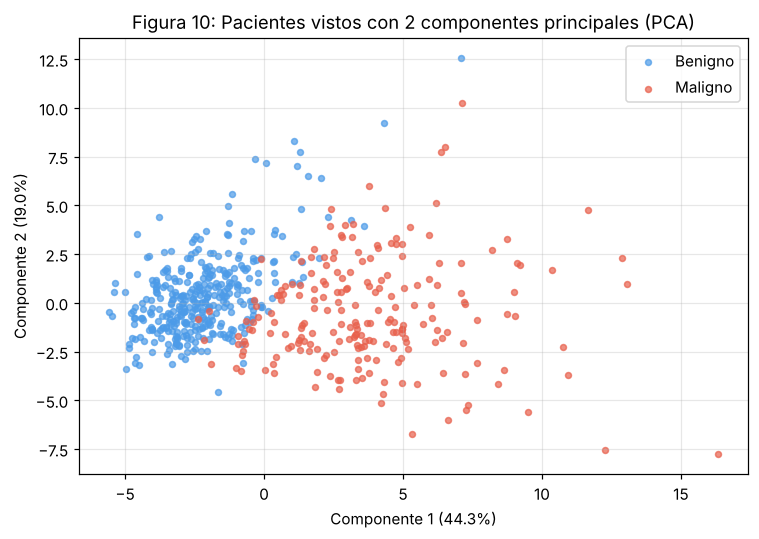

In [18]:
X_escalado = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=SEMILLA)
X_pca = pca.fit_transform(X_escalado)
var = pca.explained_variance_ratio_
print(f'Componente 1 explica el {var[0]*100:.1f}% de la información')
print(f'Componente 2 explica el {var[1]*100:.1f}% de la información')
print(f'Entre las dos: {var.sum()*100:.1f}%')

fig, ax = plt.subplots(figsize=(7, 5))
for valor, nombre, color in [(0, 'Benigno', '#4C9BE8'), (1, 'Maligno', '#E8604C')]:
    m = y == valor
    ax.scatter(X_pca[m, 0], X_pca[m, 1], s=15, alpha=0.7, color=color, label=nombre)
ax.set_title('Figura 10: Pacientes vistos con 2 componentes principales (PCA)')
ax.set_xlabel(f'Componente 1 ({var[0]*100:.1f}%)')
ax.set_ylabel(f'Componente 2 ({var[1]*100:.1f}%)')
ax.legend()
plt.tight_layout()
plt.show()

Con solo 2 componentes ya se ven dos grupos bastante separados: los benignos a la izquierda y los malignos a la derecha. Eso explica por qué los modelos de clasificación funcionan tan bien.

## 9. Clustering con K-medias

Ahora hago algo distinto: no le doy el diagnóstico al modelo. Es aprendizaje no supervisado. Le pido a K-medias que separe a los pacientes en 2 grupos solo mirando las medidas, y después comparo esos grupos con el diagnóstico real.

diagnostico     Benigno  Maligno
Grupo K-medias                  
0                   339       36
1                    18      176

Coincidencia de los grupos con el diagnóstico real: 90.5%


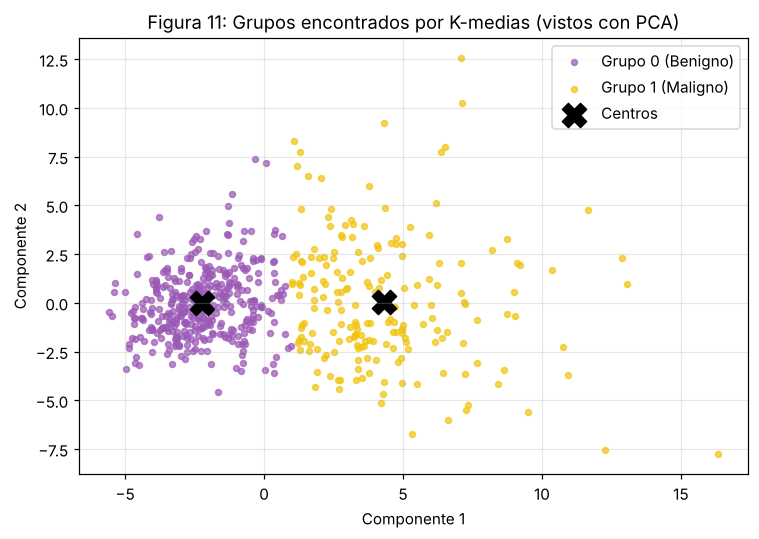

In [19]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA)
grupos = kmeans.fit_predict(X_escalado)

tabla_cl = pd.crosstab(pd.Series(grupos, name='Grupo K-medias'), df['diagnostico'])
print(tabla_cl)

# A cada grupo le asigno el diagnóstico que más se repite y calculo cuántos coinciden
asignacion = tabla_cl.idxmax(axis=1)
coincide = (pd.Series(grupos).map(asignacion).values == df['diagnostico'].values).mean()
print(f'\nCoincidencia de los grupos con el diagnóstico real: {coincide*100:.1f}%')

fig, ax = plt.subplots(figsize=(7, 5))
for g, color in [(0, '#9B59B6'), (1, '#F1C40F')]:
    m = grupos == g
    ax.scatter(X_pca[m, 0], X_pca[m, 1], s=15, alpha=0.7, color=color, label=f'Grupo {g} ({asignacion[g]})')
centros = pca.transform(kmeans.cluster_centers_)
ax.scatter(centros[:, 0], centros[:, 1], s=250, marker='X', color='black', label='Centros')
ax.set_title('Figura 11: Grupos encontrados por K-medias (vistos con PCA)')
ax.set_xlabel('Componente 1')
ax.set_ylabel('Componente 2')
ax.legend()
plt.tight_layout()
plt.show()

Sin saber el diagnóstico, K-medias armó dos grupos que coinciden bastante con benignos y malignos. Igual se equivoca más que los modelos de clasificación, porque no aprendió con las respuestas.

## 10. Conclusiones

- Los datos estaban limpios: sin faltantes ni filas repetidas.
- El análisis descriptivo mostró que los tumores malignos tienen células más grandes (radio promedio 17,46 contra 12,15 de los benignos), y la prueba t confirmó que esa diferencia es real (p mucho menor a 0,05).
- Los 4 modelos de clasificación funcionaron bien (más del 91% de exactitud), pero el mejor fue el SVM: acertó el **97,4%** de los pacientes de testeo, no dio ninguna falsa alarma y detectó **39 de los 42 malignos** (sensibilidad del 92,9%). Además fue el más estable en la validación cruzada (desvío de 0,005).
- El Árbol de Decisión fue el más flojo, pero tiene la ventaja de que se entiende cómo decide: usa sobre todo el perímetro "peor" de las células.
- Con PCA se pudo ver a los pacientes en 2 dimensiones y se notan dos grupos bastante separados.
- K-medias, sin conocer el diagnóstico, armó 2 grupos que coinciden en un **90,5%** con el diagnóstico real.
- Limitación: son solo 569 pacientes de un solo hospital. Un modelo así no reemplaza al médico, pero puede servir como ayuda para revisar casos.

Tabla final de resultados (ordenada de mejor a peor):

In [20]:
tabla_res.sort_values('Exactitud', ascending=False)

,Exactitud,Precisión,Sensibilidad,F1,AUC,CV media,CV desvío
Modelo,,,,,,,
SVM,0.974,1.000,0.929,0.963,0.995,0.971,0.005
KNN,0.939,0.973,0.857,0.911,0.982,0.974,0.018
Bayes,0.921,0.923,0.857,0.889,0.989,0.938,0.026
Árbol de Decisión,0.912,0.944,0.810,0.872,0.877,0.921,0.038
